d:\anaconda3\envs\pytorch1_12_1\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


===== 1. 生成高保真 R通道 模拟数据 =====
Generating BPSK...
Generating QPSK...
Generating PSK8...
Generating QAM16...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_24500\1234893295.py:157: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)


Generating QAM64...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_24500\1234893295.py:160: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)


Generating FSK2...

===== 2. 处理真实 IQ 文件 (提取 R 通道) =====
Processing Real File: BPSK...
Processing Real File: QAM64...
Processing Real File: QAM16...
Processing Real File: PSK8...
Processing Real File: QPSK...
Processing Real File: FSK2...
Loading ./dataset_r_channel_only\sim_train into RAM...


... (2 outputs left out)

100%|██████████| 946/946 [00:03<00:00, 311.49img/s]


Loading ./dataset_r_channel_only\real_test into RAM...


100%|██████████| 29292/29292 [01:32<00:00, 315.98img/s]



===== 开始训练 R-Channel Only TinyCNN (15 Epochs) =====
Epoch 1: Train Acc: 0.5566 | Sim Val Acc: 0.2600
Epoch 2: Train Acc: 0.8290 | Sim Val Acc: 0.7896
Epoch 3: Train Acc: 0.8874 | Sim Val Acc: 0.8890
Epoch 4: Train Acc: 0.9229 | Sim Val Acc: 0.9355
Epoch 5: Train Acc: 0.9286 | Sim Val Acc: 0.9514
Epoch 6: Train Acc: 0.9455 | Sim Val Acc: 0.9154
Epoch 7: Train Acc: 0.9458 | Sim Val Acc: 0.9641
Epoch 8: Train Acc: 0.9546 | Sim Val Acc: 0.9662
Epoch 9: Train Acc: 0.9593 | Sim Val Acc: 0.9609
Epoch 10: Train Acc: 0.9611 | Sim Val Acc: 0.9524
Epoch 11: Train Acc: 0.9696 | Sim Val Acc: 0.9715
Epoch 12: Train Acc: 0.9725 | Sim Val Acc: 0.9704
Epoch 13: Train Acc: 0.9707 | Sim Val Acc: 0.9757
Epoch 14: Train Acc: 0.9777 | Sim Val Acc: 0.9757
Epoch 15: Train Acc: 0.9803 | Sim Val Acc: 0.9651

===== 真实数据终极测试 (Only R-Channel) =====
>>> 真实数据准确率: 86.40% (25309/29292) <<<


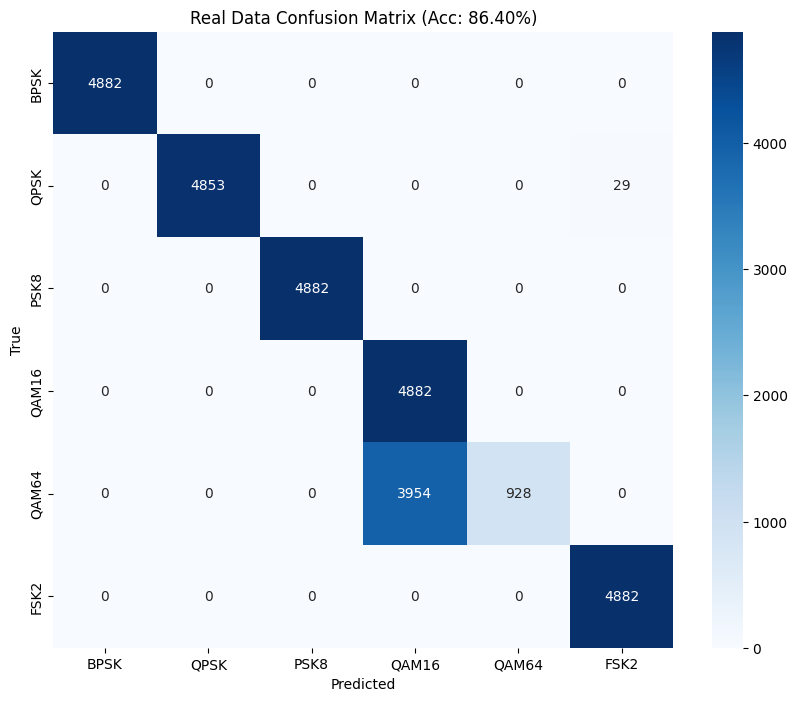

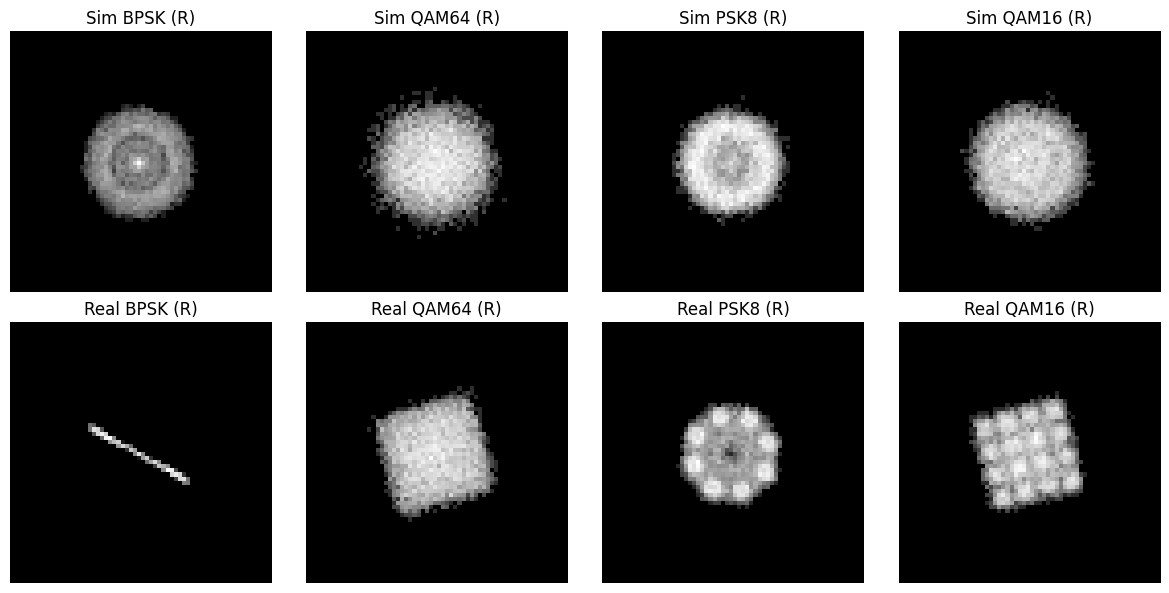

In [1]:
import os
import shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from tqdm import tqdm
import random

# ================= 0. 全局配置 =================
DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

# 核心参数
SAMPLES_PER_IMAGE = 10240
IMAGE_SIZE = 64
BATCH_SIZE = 128
LEARNING_RATE = 0.001
NUM_EPOCHS = 15

# [修改点] 输入通道改为 1 (只用 R 通道)
INPUT_CHANNELS = 1 

# 数据量配置
TOTAL_SIM_SAMPLES_PER_CLASS = 800
TRAIN_VAL_RATIO = 0.8

# 路径配置
DATASET_ROOT = "./dataset_r_channel_only" # 目录改名，避免混淆
SIM_TRAIN_DIR = os.path.join(DATASET_ROOT, "sim_train")
SIM_VAL_DIR = os.path.join(DATASET_ROOT, "sim_val")
REAL_TEST_DIR = os.path.join(DATASET_ROOT, "real_test")

# 真实数据映射
FILE_MAPPING = {
    "E:/Project/AMR-Benchmark/BPSK-03-24-25-10h52m32s937.iq": "BPSK",
    "E:/Project/AMR-Benchmark/QAM64-03-24-25-10h51m51s805.iq": "QAM64",
    "E:/Project/AMR-Benchmark/QAM16-03-24-25-10h52m09s762.iq": "QAM16",
    "E:/Project/AMR-Benchmark/PSK8-03-24-25-10h54m48s14.iq": "PSK8",
    "E:/Project/AMR-Benchmark/QPSK-03-24-25-10h53m20s46.iq": "QPSK",
    "E:/Project/AMR-Benchmark/FSK2DEV625KHZ-03-24-25-11h08m50s462.iq": "FSK2"
}

CLASS_NAMES = ["BPSK", "QPSK", "PSK8", "QAM16", "QAM64", "FSK2"]
NUM_CLASSES = len(CLASS_NAMES)


# ================= 1. 核心数学工具 =================

def fast_hist2d(x, y, bins=64, range_bounds=((-1, 1), (-1, 1))):
    x_min, x_max = range_bounds[0]
    y_min, y_max = range_bounds[1]
    x = torch.clamp(x, x_min, x_max)
    y = torch.clamp(y, y_min, y_max)
    x_idx = ((x - x_min) / (x_max - x_min) * (bins - 1)).long()
    y_idx = ((y - y_min) / (y_max - y_min) * (bins - 1)).long()
    flat_idx = y_idx * bins + x_idx
    hist = torch.bincount(flat_idx, minlength=bins*bins)
    return hist.view(bins, bins).float()

def generate_manifold_heatmap(iq_complex_data, img_size=64):
    """
    [修改点] 仅计算 R 通道 (星座图密度)
    Output: (1, H, W)
    """
    if iq_complex_data.dim() == 1:
        iq_complex_data = iq_complex_data.unsqueeze(0)
    
    iq_data = iq_complex_data.squeeze()
    if iq_data.numel() < 100: return torch.zeros(1, img_size, img_size)

    # 1. 鲁棒归一化
    scale = torch.sqrt(torch.mean(iq_data.real**2 + iq_data.imag**2)) + 1e-9
    norm_iq = iq_data / (3.0 * scale)
    
    real = norm_iq.real
    imag = norm_iq.imag
    
    # 2. 仅计算 R 通道 (I vs Q)
    bins = img_size
    hist_r = fast_hist2d(real, imag, bins=bins, range_bounds=((-1.2, 1.2), (-1.2, 1.2)))
    
    # 3. 对数压缩 + 归一化
    def process(h):
        h = torch.log1p(h)
        return (h - h.min()) / (h.max() - h.min() + 1e-8)
        
    # [修改点] 只返回一个通道
    img_tensor = process(hist_r).unsqueeze(0) # (1, H, W)
    return torch.flip(img_tensor, [1]) 

def save_tensor_as_grayscale(tensor, path):
    """[修改点] 保存为单通道灰度图"""
    tensor = tensor.detach().cpu().squeeze() # (H, W)
    arr = (tensor.numpy() * 255).astype(np.uint8)
    Image.fromarray(arr, mode='L').save(path)


# ================= 2. 高保真信号生成 (保持不变) =================

def generate_rrc_filter(N_taps, beta, sps):
    t = torch.arange(-(N_taps - 1) // 2, (N_taps - 1) // 2 + 1, dtype=torch.float32) / sps
    mid_idx = (N_taps - 1) // 2
    t[mid_idx] = 1e-8
    num = torch.sin(np.pi * t * (1 - beta)) + 4 * beta * t * torch.cos(np.pi * t * (1 + beta))
    den = np.pi * t * (1 - (4 * beta * t)**2)
    coeffs = num / den
    coeffs[mid_idx] = 1 - beta + (4 * beta / np.pi)
    return coeffs / torch.sqrt(torch.sum(coeffs**2))

def apply_channel_effects(sig, snr_db):
    N = len(sig)
    # 保持微小频偏 (-50, 50)，这对 R 通道至关重要
    freq_offset = np.random.uniform(-50, 50) 
    t = torch.arange(N, dtype=torch.float32) / 80e3
    phase_offset = np.random.uniform(0, 2*np.pi)
    rotation = torch.exp(1j * (2 * np.pi * freq_offset * t + phase_offset))
    sig = sig * rotation
    
    phase_jitter = torch.randn(N) * 0.005 
    sig = sig * torch.exp(1j * phase_jitter)
    
    g_imbalance = np.random.uniform(0.98, 1.02)
    p_imbalance = np.random.uniform(-1, 1) * np.pi/180
    real = sig.real * g_imbalance
    imag = sig.imag * np.cos(p_imbalance) - sig.real * np.sin(p_imbalance)
    sig = torch.complex(real, imag)
    
    sig_power = torch.mean(torch.abs(sig)**2)
    real_snr = snr_db + 10 
    noise_power = sig_power / (10**(real_snr/10.0))
    noise = (torch.randn_like(sig) + 1j*torch.randn_like(sig)) * torch.sqrt(noise_power/2)
    return sig + noise

def generate_sim_signal(mod_type, N, snr_db):
    Fs, Rs = 80e3, 20e3
    sps = int(Fs / Rs)
    num_symbols = int(N / sps) + 50
    
    if mod_type == "BPSK":
        syms = 2*torch.randint(0, 2, (num_symbols,)) - 1 + 0j
    elif mod_type == "QPSK":
        phase = np.pi/4 + torch.randint(0, 4, (num_symbols,)) * np.pi/2
        syms = torch.exp(1j * phase)
    elif mod_type == "PSK8":
        phase = torch.randint(0, 8, (num_symbols,)) * 2*np.pi/8
        syms = torch.exp(1j * phase)
    elif mod_type == "QAM16":
        idx = torch.randint(0, 16, (num_symbols,))
        syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)
    elif mod_type == "QAM64":
        idx = torch.randint(0, 64, (num_symbols,))
        syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)
    elif mod_type == "FSK2":
        bits = torch.randint(0, 2, (N + 100,))
        f_dev = np.random.uniform(500, 6000) 
        freqs = (bits * 2 - 1) * f_dev
        phase = 2 * np.pi * torch.cumsum(freqs/Fs, dim=0)
        sig = torch.exp(1j * phase)[:N]
        return apply_channel_effects(sig, snr_db)

    upsampled = torch.zeros(num_symbols * sps, dtype=torch.complex64)
    upsampled[::sps] = syms
    taps = 10 * sps + 1
    h = generate_rrc_filter(taps, 0.35, sps)
    real = F.conv1d(upsampled.real.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    imag = F.conv1d(upsampled.imag.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    sig = (real + 1j*imag).squeeze()
    
    if len(sig) > N: sig = sig[:N]
    else: sig = F.pad(sig, (0, N - len(sig)))
    return apply_channel_effects(sig, snr_db)


# ================= 3. 数据生成管道 =================

def generate_datasets():
    if os.path.exists(DATASET_ROOT):
        print("清理旧数据目录...")
        shutil.rmtree(DATASET_ROOT)
    
    print("===== 1. 生成高保真 R通道 模拟数据 =====")
    for cls_name in CLASS_NAMES:
        os.makedirs(os.path.join(SIM_TRAIN_DIR, cls_name), exist_ok=True)
        os.makedirs(os.path.join(SIM_VAL_DIR, cls_name), exist_ok=True)
        print(f"Generating {cls_name}...")
        for i in range(TOTAL_SIM_SAMPLES_PER_CLASS):
            target_dir = SIM_TRAIN_DIR if np.random.rand() < TRAIN_VAL_RATIO else SIM_VAL_DIR
            target_dir = os.path.join(target_dir, cls_name)
            snr = np.random.uniform(0, 20)
            sig = generate_sim_signal(cls_name, SAMPLES_PER_IMAGE, snr)
            heatmap = generate_manifold_heatmap(sig.to(DEVICE), IMAGE_SIZE)
            # 保存为单通道灰度图
            save_tensor_as_grayscale(heatmap, os.path.join(target_dir, f"{cls_name}_{i:04d}.png"))

    print("\n===== 2. 处理真实 IQ 文件 (提取 R 通道) =====")
    for file_path, label in FILE_MAPPING.items():
        if not os.path.exists(file_path): 
            print(f"Skip missing file: {file_path}")
            continue
            
        print(f"Processing Real File: {label}...")
        save_dir = os.path.join(REAL_TEST_DIR, label)
        os.makedirs(save_dir, exist_ok=True)
        
        try:
            raw = np.fromfile(file_path, dtype=np.int16)
            if len(raw) % 2 != 0: raw = raw[:-1]
            I = raw[::2].astype(np.float32)
            Q = raw[1::2].astype(np.float32)
            iq_complex = (I + 1j * Q).astype(np.complex64) / 32767.0
            
            num_slices = len(iq_complex) // SAMPLES_PER_IMAGE
            for i in range(num_slices):
                chunk = iq_complex[i*SAMPLES_PER_IMAGE : (i+1)*SAMPLES_PER_IMAGE]
                chunk_tensor = torch.from_numpy(chunk).to(DEVICE)
                heatmap = generate_manifold_heatmap(chunk_tensor, IMAGE_SIZE)
                save_tensor_as_grayscale(heatmap, os.path.join(save_dir, f"real_{i:04d}.png"))
        except Exception as e:
            print(f"Error processing {file_path}: {e}")


# ================= 4. 模型与训练 =================

class TinyCNN(nn.Module):
    def __init__(self, num_classes):
        super(TinyCNN, self).__init__()
        self.features = nn.Sequential(
            # [修改点] 输入通道为 1
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*8*8, 128), 
            nn.ReLU(), 
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )
    def forward(self, x): return self.classifier(self.features(x))

class InMemoryDataset(Dataset):
    def __init__(self, root_dir):
        self.data, self.labels = [], []
        # [修改点] 转换为 'L' (灰度) 模式，ToTensor 会自动将其变为 (1, H, W)
        self.transform = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()])
        if not os.path.exists(root_dir): return
        print(f"Loading {root_dir} into RAM...")
        files = []
        for cls_name in CLASS_NAMES:
            d = Path(root_dir) / cls_name
            if d.exists(): files.extend([(p, CLASS_NAMES.index(cls_name)) for p in d.glob("*.png")])
        with tqdm(total=len(files), unit="img") as pbar:
            for p, label in files:
                try:
                    # [修改点] convert("L")
                    with Image.open(str(p)).convert("L") as img:
                        self.data.append(self.transform(img))
                        self.labels.append(label)
                except: pass
                pbar.update(1)
    def __len__(self): return len(self.data)
    def __getitem__(self, idx): return self.data[idx], self.labels[idx]

def train_and_eval():
    train_ds = InMemoryDataset(SIM_TRAIN_DIR)
    val_ds = InMemoryDataset(SIM_VAL_DIR)
    real_ds = InMemoryDataset(REAL_TEST_DIR)
    
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    
    model = TinyCNN(NUM_CLASSES).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    
    print(f"\n===== 开始训练 R-Channel Only TinyCNN ({NUM_EPOCHS} Epochs) =====")
    for epoch in range(NUM_EPOCHS):
        model.train()
        correct, total = 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
            
        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                val_correct += preds.eq(labels).sum().item()
                val_total += labels.size(0)
        print(f"Epoch {epoch+1}: Train Acc: {correct/total:.4f} | Sim Val Acc: {val_correct/val_total:.4f}")

    if len(real_ds) > 0:
        real_loader = DataLoader(real_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        print("\n===== 真实数据终极测试 (Only R-Channel) =====")
        model.eval()
        all_preds, all_labels = [], []
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, labels in real_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                correct += preds.eq(labels).sum().item()
                total += labels.size(0)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        acc = correct / total
        print(f">>> 真实数据准确率: {acc:.2%} ({correct}/{total}) <<<")
        cm = confusion_matrix(all_labels, all_preds)
        plt.figure(figsize=(10, 8))
        sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
        plt.title(f"Real Data Confusion Matrix (Acc: {acc:.2%})")
        plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

def visualize_sim_vs_real():
    plt.figure(figsize=(12, 6))
    cols = 4
    # 随机选4个类进行可视化对比
    for i, cls in enumerate(["BPSK", "QAM64", "PSK8", "QAM16"]):
        sim_files = list(Path(SIM_TRAIN_DIR).joinpath(cls).glob("*.png"))
        real_files = list(Path(REAL_TEST_DIR).joinpath(cls).glob("*.png"))
        if sim_files:
            plt.subplot(2, cols, i+1)
            plt.imshow(Image.open(sim_files[0]), cmap='gray')
            plt.title(f"Sim {cls} (R)"); plt.axis('off')
        if real_files:
            plt.subplot(2, cols, i+1+cols)
            plt.imshow(Image.open(random.choice(real_files)), cmap='gray')
            plt.title(f"Real {cls} (R)"); plt.axis('off')
    plt.tight_layout(); plt.show()

if __name__ == "__main__":
    generate_datasets()
    train_and_eval()
    visualize_sim_vs_real()

===== 1. 生成高保真 G通道 模拟数据 =====
Generating BPSK...
Generating QPSK...
Generating PSK8...
Generating QAM16...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_24500\134631772.py:156: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)


Generating QAM64...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_24500\134631772.py:159: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)


Generating FSK2...

===== 2. 处理真实 IQ 文件 (提取 G 通道) =====
Processing Real File: BPSK...
Processing Real File: QAM64...
Processing Real File: QAM16...
Processing Real File: PSK8...
Processing Real File: QPSK...
Processing Real File: FSK2...
Loading ./dataset_g_channel_only\sim_train into RAM...


100%|██████████| 3813/3813 [00:12<00:00, 311.43img/s]


Loading ./dataset_g_channel_only\sim_val into RAM...


100%|██████████| 987/987 [00:03<00:00, 316.87img/s]


Loading ./dataset_g_channel_only\real_test into RAM...


100%|██████████| 29292/29292 [01:32<00:00, 316.94img/s]



===== 开始训练 G-Channel Only TinyCNN (15 Epochs) =====
Epoch 1: Train Acc: 0.4534 | Sim Val Acc: 0.3870
Epoch 2: Train Acc: 0.6751 | Sim Val Acc: 0.7497
Epoch 3: Train Acc: 0.7750 | Sim Val Acc: 0.9048
Epoch 4: Train Acc: 0.8266 | Sim Val Acc: 0.9078
Epoch 5: Train Acc: 0.8673 | Sim Val Acc: 0.9352
Epoch 6: Train Acc: 0.8896 | Sim Val Acc: 0.9433
Epoch 7: Train Acc: 0.8961 | Sim Val Acc: 0.9382
Epoch 8: Train Acc: 0.9150 | Sim Val Acc: 0.9341
Epoch 9: Train Acc: 0.9163 | Sim Val Acc: 0.9483
Epoch 10: Train Acc: 0.9347 | Sim Val Acc: 0.9362
Epoch 11: Train Acc: 0.9368 | Sim Val Acc: 0.9534
Epoch 12: Train Acc: 0.9457 | Sim Val Acc: 0.9493
Epoch 13: Train Acc: 0.9591 | Sim Val Acc: 0.9625
Epoch 14: Train Acc: 0.9593 | Sim Val Acc: 0.9656
Epoch 15: Train Acc: 0.9593 | Sim Val Acc: 0.9666

===== 真实数据终极测试 (Only G-Channel) =====
>>> 真实数据准确率: 44.06% (12907/29292) <<<


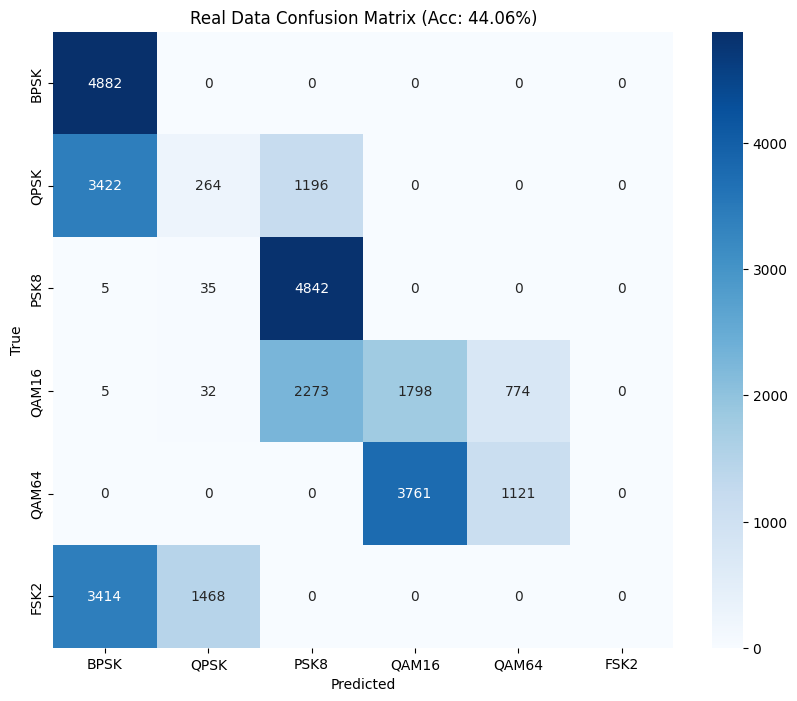

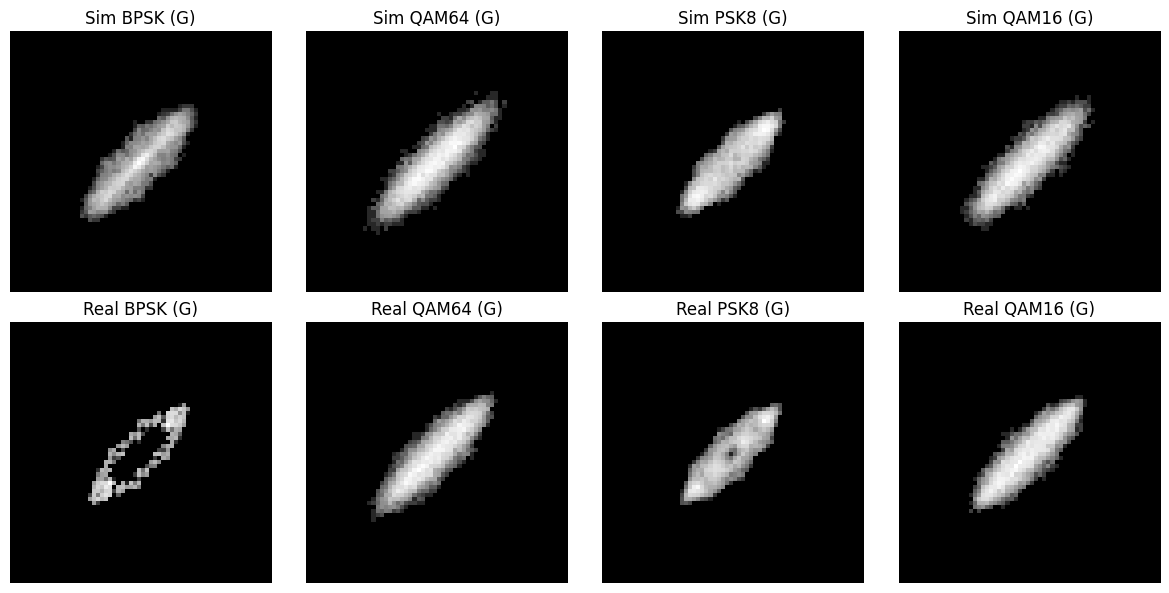

In [2]:
import os
import shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from tqdm import tqdm
import random

# ================= 0. 全局配置 =================
DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

# 核心参数
SAMPLES_PER_IMAGE = 10240
IMAGE_SIZE = 64
BATCH_SIZE = 128
LEARNING_RATE = 0.001
NUM_EPOCHS = 15

# [配置] 单通道输入
INPUT_CHANNELS = 1 

# 数据量配置
TOTAL_SIM_SAMPLES_PER_CLASS = 800
TRAIN_VAL_RATIO = 0.8

# 路径配置 (改为 G 通道专用目录)
DATASET_ROOT = "./dataset_g_channel_only" 
SIM_TRAIN_DIR = os.path.join(DATASET_ROOT, "sim_train")
SIM_VAL_DIR = os.path.join(DATASET_ROOT, "sim_val")
REAL_TEST_DIR = os.path.join(DATASET_ROOT, "real_test")

# 真实数据映射
FILE_MAPPING = {
    "E:/Project/AMR-Benchmark/BPSK-03-24-25-10h52m32s937.iq": "BPSK",
    "E:/Project/AMR-Benchmark/QAM64-03-24-25-10h51m51s805.iq": "QAM64",
    "E:/Project/AMR-Benchmark/QAM16-03-24-25-10h52m09s762.iq": "QAM16",
    "E:/Project/AMR-Benchmark/PSK8-03-24-25-10h54m48s14.iq": "PSK8",
    "E:/Project/AMR-Benchmark/QPSK-03-24-25-10h53m20s46.iq": "QPSK",
    "E:/Project/AMR-Benchmark/FSK2DEV625KHZ-03-24-25-11h08m50s462.iq": "FSK2"
}

CLASS_NAMES = ["BPSK", "QPSK", "PSK8", "QAM16", "QAM64", "FSK2"]
NUM_CLASSES = len(CLASS_NAMES)


# ================= 1. 核心数学工具 =================

def fast_hist2d(x, y, bins=64, range_bounds=((-1, 1), (-1, 1))):
    x_min, x_max = range_bounds[0]
    y_min, y_max = range_bounds[1]
    x = torch.clamp(x, x_min, x_max)
    y = torch.clamp(y, y_min, y_max)
    x_idx = ((x - x_min) / (x_max - x_min) * (bins - 1)).long()
    y_idx = ((y - y_min) / (y_max - y_min) * (bins - 1)).long()
    flat_idx = y_idx * bins + x_idx
    hist = torch.bincount(flat_idx, minlength=bins*bins)
    return hist.view(bins, bins).float()

def generate_manifold_heatmap(iq_complex_data, img_size=64):
    """
    [修改点] 仅计算 G 通道 (实部轨迹 I[t] vs I[t-1])
    Output: (1, H, W)
    """
    if iq_complex_data.dim() == 1:
        iq_complex_data = iq_complex_data.unsqueeze(0)
    
    iq_data = iq_complex_data.squeeze()
    if iq_data.numel() < 100: return torch.zeros(1, img_size, img_size)

    # 1. 鲁棒归一化
    scale = torch.sqrt(torch.mean(iq_data.real**2 + iq_data.imag**2)) + 1e-9
    norm_iq = iq_data / (3.0 * scale)
    
    # 2. 提取实部并构造延迟嵌入
    real = norm_iq.real
    x = real[1:]   # I[t]
    y = real[:-1]  # I[t-1]
    
    # 3. 计算 G 通道直方图
    bins = img_size
    hist_g = fast_hist2d(x, y, bins=bins, range_bounds=((-1.2, 1.2), (-1.2, 1.2)))
    
    # 4. 对数压缩 + 归一化
    def process(h):
        h = torch.log1p(h)
        return (h - h.min()) / (h.max() - h.min() + 1e-8)
        
    img_tensor = process(hist_g).unsqueeze(0) # (1, H, W)
    return torch.flip(img_tensor, [1]) 

def save_tensor_as_grayscale(tensor, path):
    tensor = tensor.detach().cpu().squeeze()
    arr = (tensor.numpy() * 255).astype(np.uint8)
    Image.fromarray(arr, mode='L').save(path)


# ================= 2. 高保真信号生成 (保持不变) =================

def generate_rrc_filter(N_taps, beta, sps):
    t = torch.arange(-(N_taps - 1) // 2, (N_taps - 1) // 2 + 1, dtype=torch.float32) / sps
    mid_idx = (N_taps - 1) // 2
    t[mid_idx] = 1e-8
    num = torch.sin(np.pi * t * (1 - beta)) + 4 * beta * t * torch.cos(np.pi * t * (1 + beta))
    den = np.pi * t * (1 - (4 * beta * t)**2)
    coeffs = num / den
    coeffs[mid_idx] = 1 - beta + (4 * beta / np.pi)
    return coeffs / torch.sqrt(torch.sum(coeffs**2))

def apply_channel_effects(sig, snr_db):
    N = len(sig)
    freq_offset = np.random.uniform(-50, 50) 
    t = torch.arange(N, dtype=torch.float32) / 80e3
    phase_offset = np.random.uniform(0, 2*np.pi)
    rotation = torch.exp(1j * (2 * np.pi * freq_offset * t + phase_offset))
    sig = sig * rotation
    
    phase_jitter = torch.randn(N) * 0.005 
    sig = sig * torch.exp(1j * phase_jitter)
    
    g_imbalance = np.random.uniform(0.98, 1.02)
    p_imbalance = np.random.uniform(-1, 1) * np.pi/180
    real = sig.real * g_imbalance
    imag = sig.imag * np.cos(p_imbalance) - sig.real * np.sin(p_imbalance)
    sig = torch.complex(real, imag)
    
    sig_power = torch.mean(torch.abs(sig)**2)
    real_snr = snr_db + 10 
    noise_power = sig_power / (10**(real_snr/10.0))
    noise = (torch.randn_like(sig) + 1j*torch.randn_like(sig)) * torch.sqrt(noise_power/2)
    return sig + noise

def generate_sim_signal(mod_type, N, snr_db):
    Fs, Rs = 80e3, 20e3
    sps = int(Fs / Rs)
    num_symbols = int(N / sps) + 50
    
    if mod_type == "BPSK":
        syms = 2*torch.randint(0, 2, (num_symbols,)) - 1 + 0j
    elif mod_type == "QPSK":
        phase = np.pi/4 + torch.randint(0, 4, (num_symbols,)) * np.pi/2
        syms = torch.exp(1j * phase)
    elif mod_type == "PSK8":
        phase = torch.randint(0, 8, (num_symbols,)) * 2*np.pi/8
        syms = torch.exp(1j * phase)
    elif mod_type == "QAM16":
        idx = torch.randint(0, 16, (num_symbols,))
        syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)
    elif mod_type == "QAM64":
        idx = torch.randint(0, 64, (num_symbols,))
        syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)
    elif mod_type == "FSK2":
        bits = torch.randint(0, 2, (N + 100,))
        f_dev = np.random.uniform(500, 6000) 
        freqs = (bits * 2 - 1) * f_dev
        phase = 2 * np.pi * torch.cumsum(freqs/Fs, dim=0)
        sig = torch.exp(1j * phase)[:N]
        return apply_channel_effects(sig, snr_db)

    upsampled = torch.zeros(num_symbols * sps, dtype=torch.complex64)
    upsampled[::sps] = syms
    taps = 10 * sps + 1
    h = generate_rrc_filter(taps, 0.35, sps)
    real = F.conv1d(upsampled.real.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    imag = F.conv1d(upsampled.imag.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    sig = (real + 1j*imag).squeeze()
    
    if len(sig) > N: sig = sig[:N]
    else: sig = F.pad(sig, (0, N - len(sig)))
    return apply_channel_effects(sig, snr_db)


# ================= 3. 数据生成管道 =================

def generate_datasets():
    if os.path.exists(DATASET_ROOT):
        print("清理旧数据目录...")
        shutil.rmtree(DATASET_ROOT)
    
    print("===== 1. 生成高保真 G通道 模拟数据 =====")
    for cls_name in CLASS_NAMES:
        os.makedirs(os.path.join(SIM_TRAIN_DIR, cls_name), exist_ok=True)
        os.makedirs(os.path.join(SIM_VAL_DIR, cls_name), exist_ok=True)
        print(f"Generating {cls_name}...")
        for i in range(TOTAL_SIM_SAMPLES_PER_CLASS):
            target_dir = SIM_TRAIN_DIR if np.random.rand() < TRAIN_VAL_RATIO else SIM_VAL_DIR
            target_dir = os.path.join(target_dir, cls_name)
            snr = np.random.uniform(0, 20)
            sig = generate_sim_signal(cls_name, SAMPLES_PER_IMAGE, snr)
            heatmap = generate_manifold_heatmap(sig.to(DEVICE), IMAGE_SIZE)
            save_tensor_as_grayscale(heatmap, os.path.join(target_dir, f"{cls_name}_{i:04d}.png"))

    print("\n===== 2. 处理真实 IQ 文件 (提取 G 通道) =====")
    for file_path, label in FILE_MAPPING.items():
        if not os.path.exists(file_path): 
            print(f"Skip missing file: {file_path}")
            continue
            
        print(f"Processing Real File: {label}...")
        save_dir = os.path.join(REAL_TEST_DIR, label)
        os.makedirs(save_dir, exist_ok=True)
        
        try:
            raw = np.fromfile(file_path, dtype=np.int16)
            if len(raw) % 2 != 0: raw = raw[:-1]
            I = raw[::2].astype(np.float32)
            Q = raw[1::2].astype(np.float32)
            iq_complex = (I + 1j * Q).astype(np.complex64) / 32767.0
            
            num_slices = len(iq_complex) // SAMPLES_PER_IMAGE
            for i in range(num_slices):
                chunk = iq_complex[i*SAMPLES_PER_IMAGE : (i+1)*SAMPLES_PER_IMAGE]
                chunk_tensor = torch.from_numpy(chunk).to(DEVICE)
                heatmap = generate_manifold_heatmap(chunk_tensor, IMAGE_SIZE)
                save_tensor_as_grayscale(heatmap, os.path.join(save_dir, f"real_{i:04d}.png"))
        except Exception as e:
            print(f"Error processing {file_path}: {e}")


# ================= 4. 模型与训练 =================

class TinyCNN(nn.Module):
    def __init__(self, num_classes):
        super(TinyCNN, self).__init__()
        self.features = nn.Sequential(
            # [修改点] 输入通道 1
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*8*8, 128), 
            nn.ReLU(), 
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )
    def forward(self, x): return self.classifier(self.features(x))

class InMemoryDataset(Dataset):
    def __init__(self, root_dir):
        self.data, self.labels = [], []
        self.transform = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()])
        if not os.path.exists(root_dir): return
        print(f"Loading {root_dir} into RAM...")
        files = []
        for cls_name in CLASS_NAMES:
            d = Path(root_dir) / cls_name
            if d.exists(): files.extend([(p, CLASS_NAMES.index(cls_name)) for p in d.glob("*.png")])
        with tqdm(total=len(files), unit="img") as pbar:
            for p, label in files:
                try:
                    # [修改点] 灰度读取
                    with Image.open(str(p)).convert("L") as img:
                        self.data.append(self.transform(img))
                        self.labels.append(label)
                except: pass
                pbar.update(1)
    def __len__(self): return len(self.data)
    def __getitem__(self, idx): return self.data[idx], self.labels[idx]

def train_and_eval():
    train_ds = InMemoryDataset(SIM_TRAIN_DIR)
    val_ds = InMemoryDataset(SIM_VAL_DIR)
    real_ds = InMemoryDataset(REAL_TEST_DIR)
    
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    
    model = TinyCNN(NUM_CLASSES).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    
    print(f"\n===== 开始训练 G-Channel Only TinyCNN ({NUM_EPOCHS} Epochs) =====")
    for epoch in range(NUM_EPOCHS):
        model.train()
        correct, total = 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
            
        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                val_correct += preds.eq(labels).sum().item()
                val_total += labels.size(0)
        print(f"Epoch {epoch+1}: Train Acc: {correct/total:.4f} | Sim Val Acc: {val_correct/val_total:.4f}")

    if len(real_ds) > 0:
        real_loader = DataLoader(real_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        print("\n===== 真实数据终极测试 (Only G-Channel) =====")
        model.eval()
        all_preds, all_labels = [], []
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, labels in real_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                correct += preds.eq(labels).sum().item()
                total += labels.size(0)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        acc = correct / total
        print(f">>> 真实数据准确率: {acc:.2%} ({correct}/{total}) <<<")
        cm = confusion_matrix(all_labels, all_preds)
        plt.figure(figsize=(10, 8))
        sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
        plt.title(f"Real Data Confusion Matrix (Acc: {acc:.2%})")
        plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

def visualize_sim_vs_real():
    plt.figure(figsize=(12, 6))
    cols = 4
    for i, cls in enumerate(["BPSK", "QAM64", "PSK8", "QAM16"]):
        sim_files = list(Path(SIM_TRAIN_DIR).joinpath(cls).glob("*.png"))
        real_files = list(Path(REAL_TEST_DIR).joinpath(cls).glob("*.png"))
        if sim_files:
            plt.subplot(2, cols, i+1)
            plt.imshow(Image.open(sim_files[0]), cmap='gray')
            plt.title(f"Sim {cls} (G)"); plt.axis('off')
        if real_files:
            plt.subplot(2, cols, i+1+cols)
            plt.imshow(Image.open(random.choice(real_files)), cmap='gray')
            plt.title(f"Real {cls} (G)"); plt.axis('off')
    plt.tight_layout(); plt.show()

if __name__ == "__main__":
    generate_datasets()
    train_and_eval()
    visualize_sim_vs_real()

===== 1. 生成高保真 B通道 模拟数据 =====
Generating BPSK...
Generating QPSK...
Generating PSK8...
Generating QAM16...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_24500\1107754935.py:156: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)


Generating QAM64...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_24500\1107754935.py:159: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)


Generating FSK2...

===== 2. 处理真实 IQ 文件 (提取 B 通道) =====
Processing Real File: BPSK...
Processing Real File: QAM64...
Processing Real File: QAM16...
Processing Real File: PSK8...
Processing Real File: QPSK...
Processing Real File: FSK2...
Loading ./dataset_b_channel_only\sim_train into RAM...


100%|██████████| 3812/3812 [00:12<00:00, 312.57img/s]


Loading ./dataset_b_channel_only\sim_val into RAM...


100%|██████████| 988/988 [00:03<00:00, 320.12img/s]


Loading ./dataset_b_channel_only\real_test into RAM...


100%|██████████| 29292/29292 [01:32<00:00, 317.43img/s]



===== 开始训练 B-Channel Only TinyCNN (15 Epochs) =====
Epoch 1: Train Acc: 0.4843 | Sim Val Acc: 0.5040
Epoch 2: Train Acc: 0.7164 | Sim Val Acc: 0.8269
Epoch 3: Train Acc: 0.7896 | Sim Val Acc: 0.8856
Epoch 4: Train Acc: 0.8429 | Sim Val Acc: 0.9059
Epoch 5: Train Acc: 0.8717 | Sim Val Acc: 0.9302
Epoch 6: Train Acc: 0.8848 | Sim Val Acc: 0.9332
Epoch 7: Train Acc: 0.9126 | Sim Val Acc: 0.9322
Epoch 8: Train Acc: 0.9153 | Sim Val Acc: 0.9312
Epoch 9: Train Acc: 0.9237 | Sim Val Acc: 0.9423
Epoch 10: Train Acc: 0.9297 | Sim Val Acc: 0.9403
Epoch 11: Train Acc: 0.9302 | Sim Val Acc: 0.9362
Epoch 12: Train Acc: 0.9423 | Sim Val Acc: 0.9605
Epoch 13: Train Acc: 0.9420 | Sim Val Acc: 0.9545
Epoch 14: Train Acc: 0.9554 | Sim Val Acc: 0.9615
Epoch 15: Train Acc: 0.9546 | Sim Val Acc: 0.9464

===== 真实数据终极测试 (Only B-Channel) =====
>>> 真实数据准确率: 53.91% (15792/29292) <<<


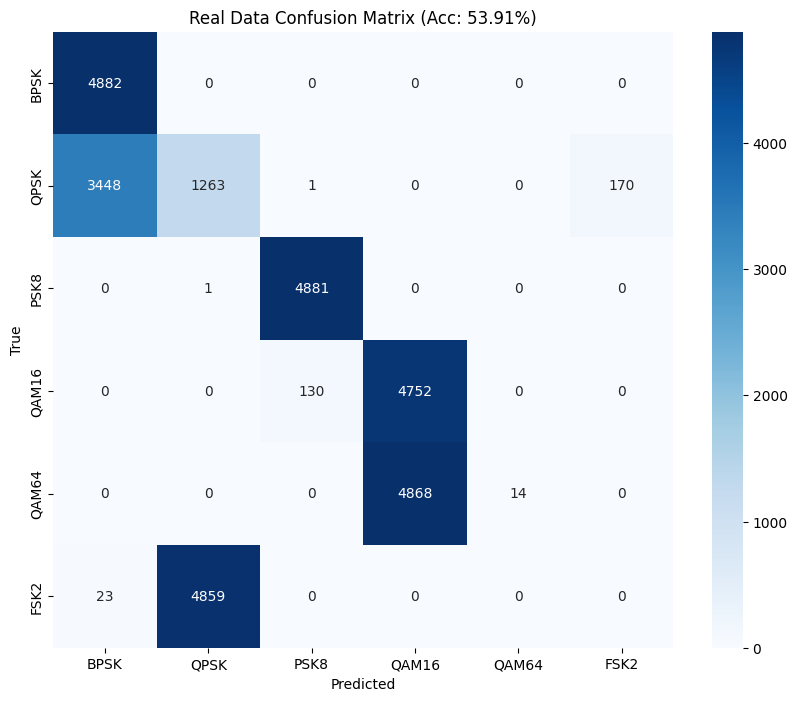

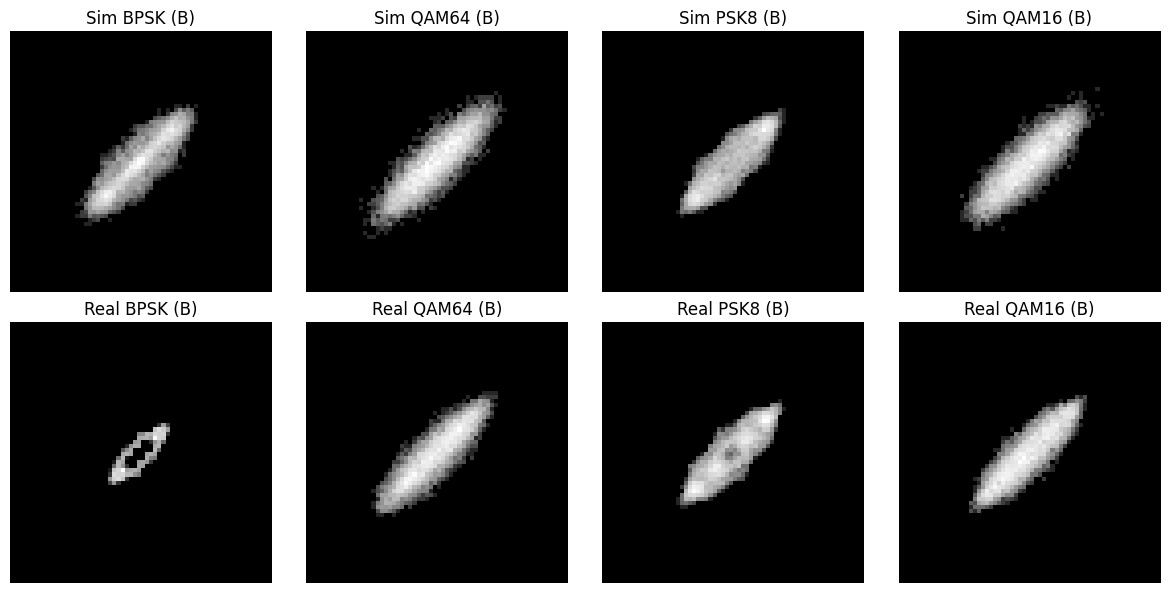

In [3]:
import os
import shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from tqdm import tqdm
import random

# ================= 0. 全局配置 =================
DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

# 核心参数
SAMPLES_PER_IMAGE = 10240
IMAGE_SIZE = 64
BATCH_SIZE = 128
LEARNING_RATE = 0.001
NUM_EPOCHS = 15

# [配置] 单通道输入
INPUT_CHANNELS = 1 

# 数据量配置
TOTAL_SIM_SAMPLES_PER_CLASS = 800
TRAIN_VAL_RATIO = 0.8

# 路径配置 (B 通道专用)
DATASET_ROOT = "./dataset_b_channel_only" 
SIM_TRAIN_DIR = os.path.join(DATASET_ROOT, "sim_train")
SIM_VAL_DIR = os.path.join(DATASET_ROOT, "sim_val")
REAL_TEST_DIR = os.path.join(DATASET_ROOT, "real_test")

# 真实数据映射
FILE_MAPPING = {
    "E:/Project/AMR-Benchmark/BPSK-03-24-25-10h52m32s937.iq": "BPSK",
    "E:/Project/AMR-Benchmark/QAM64-03-24-25-10h51m51s805.iq": "QAM64",
    "E:/Project/AMR-Benchmark/QAM16-03-24-25-10h52m09s762.iq": "QAM16",
    "E:/Project/AMR-Benchmark/PSK8-03-24-25-10h54m48s14.iq": "PSK8",
    "E:/Project/AMR-Benchmark/QPSK-03-24-25-10h53m20s46.iq": "QPSK",
    "E:/Project/AMR-Benchmark/FSK2DEV625KHZ-03-24-25-11h08m50s462.iq": "FSK2"
}

CLASS_NAMES = ["BPSK", "QPSK", "PSK8", "QAM16", "QAM64", "FSK2"]
NUM_CLASSES = len(CLASS_NAMES)


# ================= 1. 核心数学工具 =================

def fast_hist2d(x, y, bins=64, range_bounds=((-1, 1), (-1, 1))):
    x_min, x_max = range_bounds[0]
    y_min, y_max = range_bounds[1]
    x = torch.clamp(x, x_min, x_max)
    y = torch.clamp(y, y_min, y_max)
    x_idx = ((x - x_min) / (x_max - x_min) * (bins - 1)).long()
    y_idx = ((y - y_min) / (y_max - y_min) * (bins - 1)).long()
    flat_idx = y_idx * bins + x_idx
    hist = torch.bincount(flat_idx, minlength=bins*bins)
    return hist.view(bins, bins).float()

def generate_manifold_heatmap(iq_complex_data, img_size=64):
    """
    [修改点] 仅计算 B 通道 (虚部轨迹 Q[t] vs Q[t-1])
    Output: (1, H, W)
    """
    if iq_complex_data.dim() == 1:
        iq_complex_data = iq_complex_data.unsqueeze(0)
    
    iq_data = iq_complex_data.squeeze()
    if iq_data.numel() < 100: return torch.zeros(1, img_size, img_size)

    # 1. 鲁棒归一化
    scale = torch.sqrt(torch.mean(iq_data.real**2 + iq_data.imag**2)) + 1e-9
    norm_iq = iq_data / (3.0 * scale)
    
    # 2. 提取虚部 (Imaginary Part)
    imag = norm_iq.imag
    x = imag[1:]   # Q[t]
    y = imag[:-1]  # Q[t-1]
    
    # 3. 计算 B 通道直方图
    bins = img_size
    hist_b = fast_hist2d(x, y, bins=bins, range_bounds=((-1.2, 1.2), (-1.2, 1.2)))
    
    # 4. 对数压缩 + 归一化
    def process(h):
        h = torch.log1p(h)
        return (h - h.min()) / (h.max() - h.min() + 1e-8)
        
    img_tensor = process(hist_b).unsqueeze(0) # (1, H, W)
    return torch.flip(img_tensor, [1]) 

def save_tensor_as_grayscale(tensor, path):
    tensor = tensor.detach().cpu().squeeze()
    arr = (tensor.numpy() * 255).astype(np.uint8)
    Image.fromarray(arr, mode='L').save(path)


# ================= 2. 高保真信号生成 (保持不变) =================

def generate_rrc_filter(N_taps, beta, sps):
    t = torch.arange(-(N_taps - 1) // 2, (N_taps - 1) // 2 + 1, dtype=torch.float32) / sps
    mid_idx = (N_taps - 1) // 2
    t[mid_idx] = 1e-8
    num = torch.sin(np.pi * t * (1 - beta)) + 4 * beta * t * torch.cos(np.pi * t * (1 + beta))
    den = np.pi * t * (1 - (4 * beta * t)**2)
    coeffs = num / den
    coeffs[mid_idx] = 1 - beta + (4 * beta / np.pi)
    return coeffs / torch.sqrt(torch.sum(coeffs**2))

def apply_channel_effects(sig, snr_db):
    N = len(sig)
    freq_offset = np.random.uniform(-50, 50) 
    t = torch.arange(N, dtype=torch.float32) / 80e3
    phase_offset = np.random.uniform(0, 2*np.pi)
    rotation = torch.exp(1j * (2 * np.pi * freq_offset * t + phase_offset))
    sig = sig * rotation
    
    phase_jitter = torch.randn(N) * 0.005 
    sig = sig * torch.exp(1j * phase_jitter)
    
    g_imbalance = np.random.uniform(0.98, 1.02)
    p_imbalance = np.random.uniform(-1, 1) * np.pi/180
    real = sig.real * g_imbalance
    imag = sig.imag * np.cos(p_imbalance) - sig.real * np.sin(p_imbalance)
    sig = torch.complex(real, imag)
    
    sig_power = torch.mean(torch.abs(sig)**2)
    real_snr = snr_db + 10 
    noise_power = sig_power / (10**(real_snr/10.0))
    noise = (torch.randn_like(sig) + 1j*torch.randn_like(sig)) * torch.sqrt(noise_power/2)
    return sig + noise

def generate_sim_signal(mod_type, N, snr_db):
    Fs, Rs = 80e3, 20e3
    sps = int(Fs / Rs)
    num_symbols = int(N / sps) + 50
    
    if mod_type == "BPSK":
        syms = 2*torch.randint(0, 2, (num_symbols,)) - 1 + 0j
    elif mod_type == "QPSK":
        phase = np.pi/4 + torch.randint(0, 4, (num_symbols,)) * np.pi/2
        syms = torch.exp(1j * phase)
    elif mod_type == "PSK8":
        phase = torch.randint(0, 8, (num_symbols,)) * 2*np.pi/8
        syms = torch.exp(1j * phase)
    elif mod_type == "QAM16":
        idx = torch.randint(0, 16, (num_symbols,))
        syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)
    elif mod_type == "QAM64":
        idx = torch.randint(0, 64, (num_symbols,))
        syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)
    elif mod_type == "FSK2":
        bits = torch.randint(0, 2, (N + 100,))
        f_dev = np.random.uniform(500, 6000) 
        freqs = (bits * 2 - 1) * f_dev
        phase = 2 * np.pi * torch.cumsum(freqs/Fs, dim=0)
        sig = torch.exp(1j * phase)[:N]
        return apply_channel_effects(sig, snr_db)

    upsampled = torch.zeros(num_symbols * sps, dtype=torch.complex64)
    upsampled[::sps] = syms
    taps = 10 * sps + 1
    h = generate_rrc_filter(taps, 0.35, sps)
    real = F.conv1d(upsampled.real.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    imag = F.conv1d(upsampled.imag.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    sig = (real + 1j*imag).squeeze()
    
    if len(sig) > N: sig = sig[:N]
    else: sig = F.pad(sig, (0, N - len(sig)))
    return apply_channel_effects(sig, snr_db)


# ================= 3. 数据生成管道 =================

def generate_datasets():
    if os.path.exists(DATASET_ROOT):
        print("清理旧数据目录...")
        shutil.rmtree(DATASET_ROOT)
    
    print("===== 1. 生成高保真 B通道 模拟数据 =====")
    for cls_name in CLASS_NAMES:
        os.makedirs(os.path.join(SIM_TRAIN_DIR, cls_name), exist_ok=True)
        os.makedirs(os.path.join(SIM_VAL_DIR, cls_name), exist_ok=True)
        print(f"Generating {cls_name}...")
        for i in range(TOTAL_SIM_SAMPLES_PER_CLASS):
            target_dir = SIM_TRAIN_DIR if np.random.rand() < TRAIN_VAL_RATIO else SIM_VAL_DIR
            target_dir = os.path.join(target_dir, cls_name)
            snr = np.random.uniform(0, 20)
            sig = generate_sim_signal(cls_name, SAMPLES_PER_IMAGE, snr)
            heatmap = generate_manifold_heatmap(sig.to(DEVICE), IMAGE_SIZE)
            save_tensor_as_grayscale(heatmap, os.path.join(target_dir, f"{cls_name}_{i:04d}.png"))

    print("\n===== 2. 处理真实 IQ 文件 (提取 B 通道) =====")
    for file_path, label in FILE_MAPPING.items():
        if not os.path.exists(file_path): 
            print(f"Skip missing file: {file_path}")
            continue
            
        print(f"Processing Real File: {label}...")
        save_dir = os.path.join(REAL_TEST_DIR, label)
        os.makedirs(save_dir, exist_ok=True)
        
        try:
            raw = np.fromfile(file_path, dtype=np.int16)
            if len(raw) % 2 != 0: raw = raw[:-1]
            I = raw[::2].astype(np.float32)
            Q = raw[1::2].astype(np.float32)
            iq_complex = (I + 1j * Q).astype(np.complex64) / 32767.0
            
            num_slices = len(iq_complex) // SAMPLES_PER_IMAGE
            for i in range(num_slices):
                chunk = iq_complex[i*SAMPLES_PER_IMAGE : (i+1)*SAMPLES_PER_IMAGE]
                chunk_tensor = torch.from_numpy(chunk).to(DEVICE)
                heatmap = generate_manifold_heatmap(chunk_tensor, IMAGE_SIZE)
                save_tensor_as_grayscale(heatmap, os.path.join(save_dir, f"real_{i:04d}.png"))
        except Exception as e:
            print(f"Error processing {file_path}: {e}")


# ================= 4. 模型与训练 =================

class TinyCNN(nn.Module):
    def __init__(self, num_classes):
        super(TinyCNN, self).__init__()
        self.features = nn.Sequential(
            # [修改点] 输入通道 1
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*8*8, 128), 
            nn.ReLU(), 
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )
    def forward(self, x): return self.classifier(self.features(x))

class InMemoryDataset(Dataset):
    def __init__(self, root_dir):
        self.data, self.labels = [], []
        self.transform = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()])
        if not os.path.exists(root_dir): return
        print(f"Loading {root_dir} into RAM...")
        files = []
        for cls_name in CLASS_NAMES:
            d = Path(root_dir) / cls_name
            if d.exists(): files.extend([(p, CLASS_NAMES.index(cls_name)) for p in d.glob("*.png")])
        with tqdm(total=len(files), unit="img") as pbar:
            for p, label in files:
                try:
                    # [修改点] 灰度读取
                    with Image.open(str(p)).convert("L") as img:
                        self.data.append(self.transform(img))
                        self.labels.append(label)
                except: pass
                pbar.update(1)
    def __len__(self): return len(self.data)
    def __getitem__(self, idx): return self.data[idx], self.labels[idx]

def train_and_eval():
    train_ds = InMemoryDataset(SIM_TRAIN_DIR)
    val_ds = InMemoryDataset(SIM_VAL_DIR)
    real_ds = InMemoryDataset(REAL_TEST_DIR)
    
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    
    model = TinyCNN(NUM_CLASSES).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    
    print(f"\n===== 开始训练 B-Channel Only TinyCNN ({NUM_EPOCHS} Epochs) =====")
    for epoch in range(NUM_EPOCHS):
        model.train()
        correct, total = 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
            
        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                val_correct += preds.eq(labels).sum().item()
                val_total += labels.size(0)
        print(f"Epoch {epoch+1}: Train Acc: {correct/total:.4f} | Sim Val Acc: {val_correct/val_total:.4f}")

    if len(real_ds) > 0:
        real_loader = DataLoader(real_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        print("\n===== 真实数据终极测试 (Only B-Channel) =====")
        model.eval()
        all_preds, all_labels = [], []
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, labels in real_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                correct += preds.eq(labels).sum().item()
                total += labels.size(0)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        acc = correct / total
        print(f">>> 真实数据准确率: {acc:.2%} ({correct}/{total}) <<<")
        cm = confusion_matrix(all_labels, all_preds)
        plt.figure(figsize=(10, 8))
        sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
        plt.title(f"Real Data Confusion Matrix (Acc: {acc:.2%})")
        plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

def visualize_sim_vs_real():
    plt.figure(figsize=(12, 6))
    cols = 4
    for i, cls in enumerate(["BPSK", "QAM64", "PSK8", "QAM16"]):
        sim_files = list(Path(SIM_TRAIN_DIR).joinpath(cls).glob("*.png"))
        real_files = list(Path(REAL_TEST_DIR).joinpath(cls).glob("*.png"))
        if sim_files:
            plt.subplot(2, cols, i+1)
            plt.imshow(Image.open(sim_files[0]), cmap='gray')
            plt.title(f"Sim {cls} (B)"); plt.axis('off')
        if real_files:
            plt.subplot(2, cols, i+1+cols)
            plt.imshow(Image.open(random.choice(real_files)), cmap='gray')
            plt.title(f"Real {cls} (B)"); plt.axis('off')
    plt.tight_layout(); plt.show()

if __name__ == "__main__":
    generate_datasets()
    train_and_eval()
    visualize_sim_vs_real()

===== 1. 生成高保真 A通道 模拟数据 =====
Generating BPSK...
Generating QPSK...
Generating PSK8...
Generating QAM16...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_24500\2864264838.py:161: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)


Generating QAM64...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_24500\2864264838.py:164: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)


Generating FSK2...

===== 2. 处理真实 IQ 文件 (提取 A 通道) =====
Processing Real File: BPSK...
Processing Real File: QAM64...
Processing Real File: QAM16...
Processing Real File: PSK8...
Processing Real File: QPSK...
Processing Real File: FSK2...
Loading ./dataset_a_channel_only\sim_train into RAM...


100%|██████████| 3745/3745 [00:12<00:00, 300.52img/s]


Loading ./dataset_a_channel_only\sim_val into RAM...


100%|██████████| 1055/1055 [00:03<00:00, 289.34img/s]


Loading ./dataset_a_channel_only\real_test into RAM...


100%|██████████| 29292/29292 [01:38<00:00, 296.78img/s]



===== 开始训练 A-Channel Only TinyCNN (15 Epochs) =====
Epoch 1: Train Acc: 0.5570 | Sim Val Acc: 0.2370
Epoch 2: Train Acc: 0.8454 | Sim Val Acc: 0.9346
Epoch 3: Train Acc: 0.9039 | Sim Val Acc: 0.9517
Epoch 4: Train Acc: 0.9319 | Sim Val Acc: 0.9592
Epoch 5: Train Acc: 0.9437 | Sim Val Acc: 0.9630
Epoch 6: Train Acc: 0.9514 | Sim Val Acc: 0.9725
Epoch 7: Train Acc: 0.9583 | Sim Val Acc: 0.9735
Epoch 8: Train Acc: 0.9672 | Sim Val Acc: 0.9791
Epoch 9: Train Acc: 0.9712 | Sim Val Acc: 0.9791
Epoch 10: Train Acc: 0.9752 | Sim Val Acc: 0.9706
Epoch 11: Train Acc: 0.9749 | Sim Val Acc: 0.9791
Epoch 12: Train Acc: 0.9808 | Sim Val Acc: 0.9810
Epoch 13: Train Acc: 0.9776 | Sim Val Acc: 0.9839
Epoch 14: Train Acc: 0.9824 | Sim Val Acc: 0.9839
Epoch 15: Train Acc: 0.9797 | Sim Val Acc: 0.9820

===== 真实数据终极测试 (Only A-Channel) =====
>>> 真实数据准确率: 98.64% (28894/29292) <<<


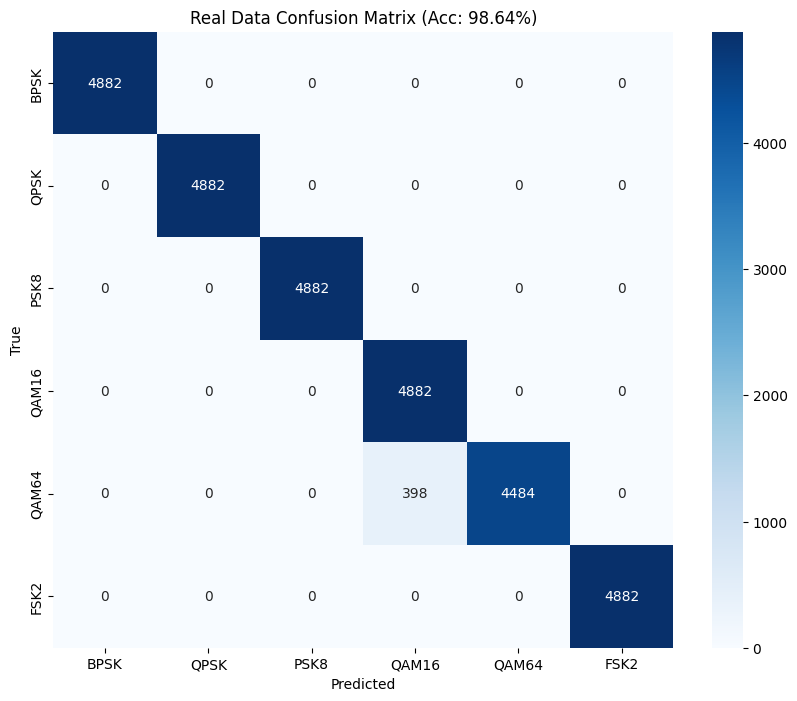

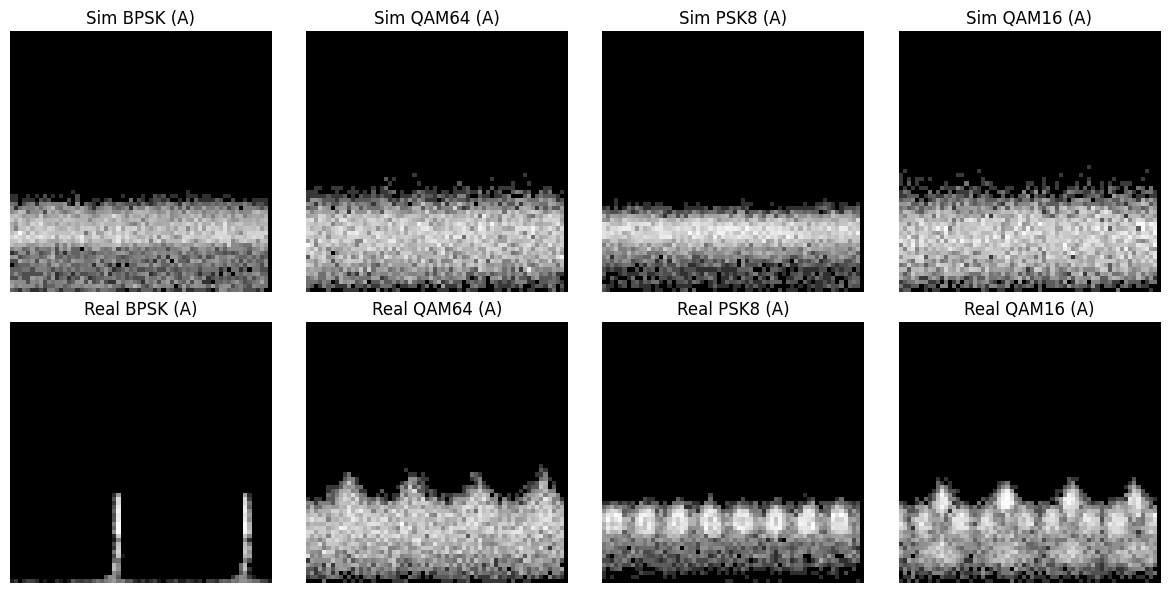

In [4]:
import os
import shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from tqdm import tqdm
import random

# ================= 0. 全局配置 =================
DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

# 核心参数
SAMPLES_PER_IMAGE = 10240
IMAGE_SIZE = 64
BATCH_SIZE = 128
LEARNING_RATE = 0.001
NUM_EPOCHS = 15

# [配置] 单通道输入
INPUT_CHANNELS = 1 

# 数据量配置
TOTAL_SIM_SAMPLES_PER_CLASS = 800
TRAIN_VAL_RATIO = 0.8

# 路径配置 (A 通道专用)
DATASET_ROOT = "./dataset_a_channel_only" 
SIM_TRAIN_DIR = os.path.join(DATASET_ROOT, "sim_train")
SIM_VAL_DIR = os.path.join(DATASET_ROOT, "sim_val")
REAL_TEST_DIR = os.path.join(DATASET_ROOT, "real_test")

# 真实数据映射
FILE_MAPPING = {
    "E:/Project/AMR-Benchmark/BPSK-03-24-25-10h52m32s937.iq": "BPSK",
    "E:/Project/AMR-Benchmark/QAM64-03-24-25-10h51m51s805.iq": "QAM64",
    "E:/Project/AMR-Benchmark/QAM16-03-24-25-10h52m09s762.iq": "QAM16",
    "E:/Project/AMR-Benchmark/PSK8-03-24-25-10h54m48s14.iq": "PSK8",
    "E:/Project/AMR-Benchmark/QPSK-03-24-25-10h53m20s46.iq": "QPSK",
    "E:/Project/AMR-Benchmark/FSK2DEV625KHZ-03-24-25-11h08m50s462.iq": "FSK2"
}

CLASS_NAMES = ["BPSK", "QPSK", "PSK8", "QAM16", "QAM64", "FSK2"]
NUM_CLASSES = len(CLASS_NAMES)


# ================= 1. 核心数学工具 =================

def fast_hist2d(x, y, bins=64, range_bounds=((-1, 1), (-1, 1))):
    x_min, x_max = range_bounds[0]
    y_min, y_max = range_bounds[1]
    x = torch.clamp(x, x_min, x_max)
    y = torch.clamp(y, y_min, y_max)
    x_idx = ((x - x_min) / (x_max - x_min) * (bins - 1)).long()
    y_idx = ((y - y_min) / (y_max - y_min) * (bins - 1)).long()
    flat_idx = y_idx * bins + x_idx
    hist = torch.bincount(flat_idx, minlength=bins*bins)
    return hist.view(bins, bins).float()

def generate_manifold_heatmap(iq_complex_data, img_size=64):
    """
    [修改点] 仅计算 A 通道 (极坐标密度 Phase vs Magnitude)
    Output: (1, H, W)
    """
    if iq_complex_data.dim() == 1:
        iq_complex_data = iq_complex_data.unsqueeze(0)
    
    iq_data = iq_complex_data.squeeze()
    if iq_data.numel() < 100: return torch.zeros(1, img_size, img_size)

    # 1. 鲁棒归一化
    scale = torch.sqrt(torch.mean(iq_data.real**2 + iq_data.imag**2)) + 1e-9
    norm_iq = iq_data / (3.0 * scale)
    
    # 2. 提取极坐标分量
    # 相位 [-1, 1]
    phase = torch.angle(norm_iq) / np.pi 
    # 幅度 [0, inf)
    mag = torch.abs(norm_iq)
    
    # 3. 计算 A 通道直方图
    # X轴: 相位 [-1.0, 1.0]
    # Y轴: 幅度 [0.0, 1.5]
    bins = img_size
    hist_a = fast_hist2d(phase, mag, bins=bins, range_bounds=((-1.0, 1.0), (0.0, 1.5)))
    
    # 4. 对数压缩 + 归一化
    def process(h):
        h = torch.log1p(h)
        return (h - h.min()) / (h.max() - h.min() + 1e-8)
        
    img_tensor = process(hist_a).unsqueeze(0) # (1, H, W)
    
    # 注意：这里需要翻转 Y 轴，让幅度 0 在下方，大在上方，符合直觉
    return torch.flip(img_tensor, [1]) 

def save_tensor_as_grayscale(tensor, path):
    tensor = tensor.detach().cpu().squeeze()
    arr = (tensor.numpy() * 255).astype(np.uint8)
    Image.fromarray(arr, mode='L').save(path)


# ================= 2. 高保真信号生成 (保持不变) =================

def generate_rrc_filter(N_taps, beta, sps):
    t = torch.arange(-(N_taps - 1) // 2, (N_taps - 1) // 2 + 1, dtype=torch.float32) / sps
    mid_idx = (N_taps - 1) // 2
    t[mid_idx] = 1e-8
    num = torch.sin(np.pi * t * (1 - beta)) + 4 * beta * t * torch.cos(np.pi * t * (1 + beta))
    den = np.pi * t * (1 - (4 * beta * t)**2)
    coeffs = num / den
    coeffs[mid_idx] = 1 - beta + (4 * beta / np.pi)
    return coeffs / torch.sqrt(torch.sum(coeffs**2))

def apply_channel_effects(sig, snr_db):
    N = len(sig)
    freq_offset = np.random.uniform(-50, 50) 
    t = torch.arange(N, dtype=torch.float32) / 80e3
    phase_offset = np.random.uniform(0, 2*np.pi)
    rotation = torch.exp(1j * (2 * np.pi * freq_offset * t + phase_offset))
    sig = sig * rotation
    
    phase_jitter = torch.randn(N) * 0.005 
    sig = sig * torch.exp(1j * phase_jitter)
    
    g_imbalance = np.random.uniform(0.98, 1.02)
    p_imbalance = np.random.uniform(-1, 1) * np.pi/180
    real = sig.real * g_imbalance
    imag = sig.imag * np.cos(p_imbalance) - sig.real * np.sin(p_imbalance)
    sig = torch.complex(real, imag)
    
    sig_power = torch.mean(torch.abs(sig)**2)
    real_snr = snr_db + 10 
    noise_power = sig_power / (10**(real_snr/10.0))
    noise = (torch.randn_like(sig) + 1j*torch.randn_like(sig)) * torch.sqrt(noise_power/2)
    return sig + noise

def generate_sim_signal(mod_type, N, snr_db):
    Fs, Rs = 80e3, 20e3
    sps = int(Fs / Rs)
    num_symbols = int(N / sps) + 50
    
    if mod_type == "BPSK":
        syms = 2*torch.randint(0, 2, (num_symbols,)) - 1 + 0j
    elif mod_type == "QPSK":
        phase = np.pi/4 + torch.randint(0, 4, (num_symbols,)) * np.pi/2
        syms = torch.exp(1j * phase)
    elif mod_type == "PSK8":
        phase = torch.randint(0, 8, (num_symbols,)) * 2*np.pi/8
        syms = torch.exp(1j * phase)
    elif mod_type == "QAM16":
        idx = torch.randint(0, 16, (num_symbols,))
        syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)
    elif mod_type == "QAM64":
        idx = torch.randint(0, 64, (num_symbols,))
        syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)
    elif mod_type == "FSK2":
        bits = torch.randint(0, 2, (N + 100,))
        f_dev = np.random.uniform(500, 6000) 
        freqs = (bits * 2 - 1) * f_dev
        phase = 2 * np.pi * torch.cumsum(freqs/Fs, dim=0)
        sig = torch.exp(1j * phase)[:N]
        return apply_channel_effects(sig, snr_db)

    upsampled = torch.zeros(num_symbols * sps, dtype=torch.complex64)
    upsampled[::sps] = syms
    taps = 10 * sps + 1
    h = generate_rrc_filter(taps, 0.35, sps)
    real = F.conv1d(upsampled.real.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    imag = F.conv1d(upsampled.imag.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    sig = (real + 1j*imag).squeeze()
    
    if len(sig) > N: sig = sig[:N]
    else: sig = F.pad(sig, (0, N - len(sig)))
    return apply_channel_effects(sig, snr_db)


# ================= 3. 数据生成管道 =================

def generate_datasets():
    if os.path.exists(DATASET_ROOT):
        print("清理旧数据目录...")
        shutil.rmtree(DATASET_ROOT)
    
    print("===== 1. 生成高保真 A通道 模拟数据 =====")
    for cls_name in CLASS_NAMES:
        os.makedirs(os.path.join(SIM_TRAIN_DIR, cls_name), exist_ok=True)
        os.makedirs(os.path.join(SIM_VAL_DIR, cls_name), exist_ok=True)
        print(f"Generating {cls_name}...")
        for i in range(TOTAL_SIM_SAMPLES_PER_CLASS):
            target_dir = SIM_TRAIN_DIR if np.random.rand() < TRAIN_VAL_RATIO else SIM_VAL_DIR
            target_dir = os.path.join(target_dir, cls_name)
            snr = np.random.uniform(0, 20)
            sig = generate_sim_signal(cls_name, SAMPLES_PER_IMAGE, snr)
            heatmap = generate_manifold_heatmap(sig.to(DEVICE), IMAGE_SIZE)
            save_tensor_as_grayscale(heatmap, os.path.join(target_dir, f"{cls_name}_{i:04d}.png"))

    print("\n===== 2. 处理真实 IQ 文件 (提取 A 通道) =====")
    for file_path, label in FILE_MAPPING.items():
        if not os.path.exists(file_path): 
            print(f"Skip missing file: {file_path}")
            continue
            
        print(f"Processing Real File: {label}...")
        save_dir = os.path.join(REAL_TEST_DIR, label)
        os.makedirs(save_dir, exist_ok=True)
        
        try:
            raw = np.fromfile(file_path, dtype=np.int16)
            if len(raw) % 2 != 0: raw = raw[:-1]
            I = raw[::2].astype(np.float32)
            Q = raw[1::2].astype(np.float32)
            iq_complex = (I + 1j * Q).astype(np.complex64) / 32767.0
            
            num_slices = len(iq_complex) // SAMPLES_PER_IMAGE
            for i in range(num_slices):
                chunk = iq_complex[i*SAMPLES_PER_IMAGE : (i+1)*SAMPLES_PER_IMAGE]
                chunk_tensor = torch.from_numpy(chunk).to(DEVICE)
                heatmap = generate_manifold_heatmap(chunk_tensor, IMAGE_SIZE)
                save_tensor_as_grayscale(heatmap, os.path.join(save_dir, f"real_{i:04d}.png"))
        except Exception as e:
            print(f"Error processing {file_path}: {e}")


# ================= 4. 模型与训练 =================

class TinyCNN(nn.Module):
    def __init__(self, num_classes):
        super(TinyCNN, self).__init__()
        self.features = nn.Sequential(
            # [修改点] 输入通道 1
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*8*8, 128), 
            nn.ReLU(), 
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )
    def forward(self, x): return self.classifier(self.features(x))

class InMemoryDataset(Dataset):
    def __init__(self, root_dir):
        self.data, self.labels = [], []
        self.transform = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()])
        if not os.path.exists(root_dir): return
        print(f"Loading {root_dir} into RAM...")
        files = []
        for cls_name in CLASS_NAMES:
            d = Path(root_dir) / cls_name
            if d.exists(): files.extend([(p, CLASS_NAMES.index(cls_name)) for p in d.glob("*.png")])
        with tqdm(total=len(files), unit="img") as pbar:
            for p, label in files:
                try:
                    # [修改点] 灰度读取
                    with Image.open(str(p)).convert("L") as img:
                        self.data.append(self.transform(img))
                        self.labels.append(label)
                except: pass
                pbar.update(1)
    def __len__(self): return len(self.data)
    def __getitem__(self, idx): return self.data[idx], self.labels[idx]

def train_and_eval():
    train_ds = InMemoryDataset(SIM_TRAIN_DIR)
    val_ds = InMemoryDataset(SIM_VAL_DIR)
    real_ds = InMemoryDataset(REAL_TEST_DIR)
    
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    
    model = TinyCNN(NUM_CLASSES).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    
    print(f"\n===== 开始训练 A-Channel Only TinyCNN ({NUM_EPOCHS} Epochs) =====")
    for epoch in range(NUM_EPOCHS):
        model.train()
        correct, total = 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
            
        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                val_correct += preds.eq(labels).sum().item()
                val_total += labels.size(0)
        print(f"Epoch {epoch+1}: Train Acc: {correct/total:.4f} | Sim Val Acc: {val_correct/val_total:.4f}")

    if len(real_ds) > 0:
        real_loader = DataLoader(real_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        print("\n===== 真实数据终极测试 (Only A-Channel) =====")
        model.eval()
        all_preds, all_labels = [], []
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, labels in real_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                correct += preds.eq(labels).sum().item()
                total += labels.size(0)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        acc = correct / total
        print(f">>> 真实数据准确率: {acc:.2%} ({correct}/{total}) <<<")
        cm = confusion_matrix(all_labels, all_preds)
        plt.figure(figsize=(10, 8))
        sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
        plt.title(f"Real Data Confusion Matrix (Acc: {acc:.2%})")
        plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

def visualize_sim_vs_real():
    plt.figure(figsize=(12, 6))
    cols = 4
    for i, cls in enumerate(["BPSK", "QAM64", "PSK8", "QAM16"]):
        sim_files = list(Path(SIM_TRAIN_DIR).joinpath(cls).glob("*.png"))
        real_files = list(Path(REAL_TEST_DIR).joinpath(cls).glob("*.png"))
        if sim_files:
            plt.subplot(2, cols, i+1)
            plt.imshow(Image.open(sim_files[0]), cmap='gray')
            plt.title(f"Sim {cls} (A)"); plt.axis('off')
        if real_files:
            plt.subplot(2, cols, i+1+cols)
            plt.imshow(Image.open(random.choice(real_files)), cmap='gray')
            plt.title(f"Real {cls} (A)"); plt.axis('off')
    plt.tight_layout(); plt.show()

if __name__ == "__main__":
    generate_datasets()
    train_and_eval()
    visualize_sim_vs_real()

===== 1. 生成高保真 R+A 双通道 模拟数据 =====
Generating BPSK...
Generating QPSK...
Generating PSK8...
Generating QAM16...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_24500\3446229256.py:180: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)


Generating QAM64...


C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_24500\3446229256.py:183: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)


Generating FSK2...

===== 2. 处理真实 IQ 文件 (提取 R+A 通道) =====
Processing Real File: BPSK...
Processing Real File: QAM64...
Processing Real File: QAM16...
Processing Real File: PSK8...
Processing Real File: QPSK...
Processing Real File: FSK2...
Loading ./dataset_dual_RA\sim_train into RAM...


100%|██████████| 3888/3888 [00:16<00:00, 241.07img/s]


Loading ./dataset_dual_RA\sim_val into RAM...


100%|██████████| 912/912 [00:03<00:00, 262.35img/s]


Loading ./dataset_dual_RA\real_test into RAM...


100%|██████████| 29292/29292 [01:54<00:00, 256.49img/s]



===== 开始训练 Dual-Channel (R+A) TinyCNN (15 Epochs) =====
Epoch 1: Train Acc: 0.5872 | Sim Val Acc: 0.6579
Epoch 2: Train Acc: 0.8817 | Sim Val Acc: 0.9353
Epoch 3: Train Acc: 0.9411 | Sim Val Acc: 0.9748
Epoch 4: Train Acc: 0.9573 | Sim Val Acc: 0.9825
Epoch 5: Train Acc: 0.9640 | Sim Val Acc: 0.9879
Epoch 6: Train Acc: 0.9671 | Sim Val Acc: 0.9890
Epoch 7: Train Acc: 0.9699 | Sim Val Acc: 0.9890
Epoch 8: Train Acc: 0.9789 | Sim Val Acc: 0.9836
Epoch 9: Train Acc: 0.9797 | Sim Val Acc: 0.9890
Epoch 10: Train Acc: 0.9753 | Sim Val Acc: 0.9912
Epoch 11: Train Acc: 0.9802 | Sim Val Acc: 0.9814
Epoch 12: Train Acc: 0.9812 | Sim Val Acc: 0.9901
Epoch 13: Train Acc: 0.9853 | Sim Val Acc: 0.9857
Epoch 14: Train Acc: 0.9815 | Sim Val Acc: 0.9879
Epoch 15: Train Acc: 0.9825 | Sim Val Acc: 0.9923

===== 真实数据终极测试 (Dual-Channel R+A) =====
>>> 真实数据准确率: 99.66% (29192/29292) <<<


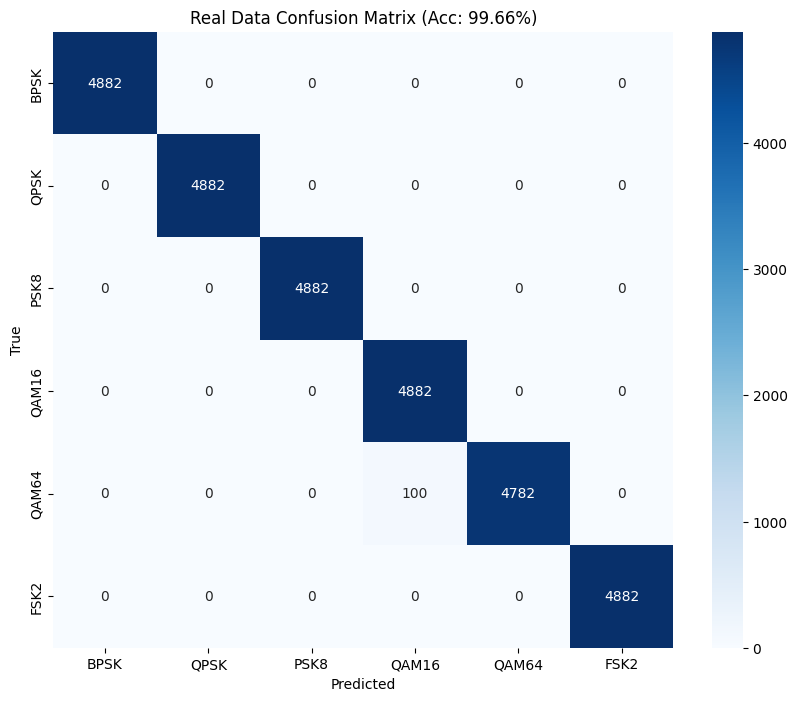

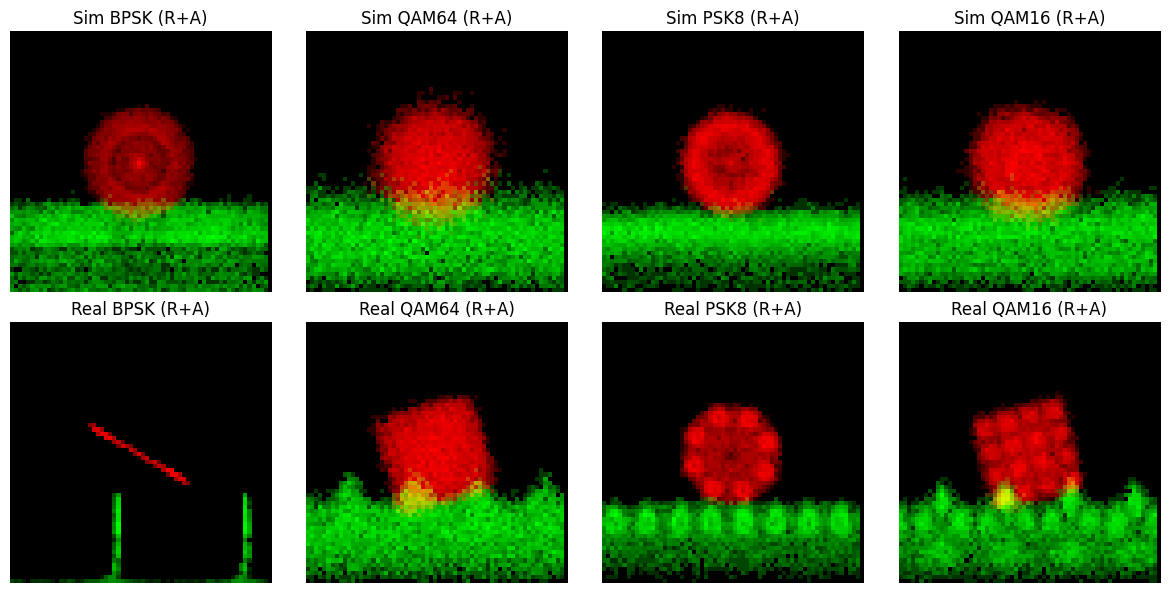

In [5]:
import os
import shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from tqdm import tqdm
import random

# ================= 0. 全局配置 =================
DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

# 核心参数
SAMPLES_PER_IMAGE = 10240
IMAGE_SIZE = 64
BATCH_SIZE = 128
LEARNING_RATE = 0.001
NUM_EPOCHS = 15

# [配置] 双通道输入
INPUT_CHANNELS = 2

# 数据量配置
TOTAL_SIM_SAMPLES_PER_CLASS = 800
TRAIN_VAL_RATIO = 0.8

# 路径配置 (R+A 双通道专用)
DATASET_ROOT = "./dataset_dual_RA" 
SIM_TRAIN_DIR = os.path.join(DATASET_ROOT, "sim_train")
SIM_VAL_DIR = os.path.join(DATASET_ROOT, "sim_val")
REAL_TEST_DIR = os.path.join(DATASET_ROOT, "real_test")

# 真实数据映射
FILE_MAPPING = {
    "E:/Project/AMR-Benchmark/BPSK-03-24-25-10h52m32s937.iq": "BPSK",
    "E:/Project/AMR-Benchmark/QAM64-03-24-25-10h51m51s805.iq": "QAM64",
    "E:/Project/AMR-Benchmark/QAM16-03-24-25-10h52m09s762.iq": "QAM16",
    "E:/Project/AMR-Benchmark/PSK8-03-24-25-10h54m48s14.iq": "PSK8",
    "E:/Project/AMR-Benchmark/QPSK-03-24-25-10h53m20s46.iq": "QPSK",
    "E:/Project/AMR-Benchmark/FSK2DEV625KHZ-03-24-25-11h08m50s462.iq": "FSK2"
}

CLASS_NAMES = ["BPSK", "QPSK", "PSK8", "QAM16", "QAM64", "FSK2"]
NUM_CLASSES = len(CLASS_NAMES)


# ================= 1. 核心数学工具 =================

def fast_hist2d(x, y, bins=64, range_bounds=((-1, 1), (-1, 1))):
    x_min, x_max = range_bounds[0]
    y_min, y_max = range_bounds[1]
    x = torch.clamp(x, x_min, x_max)
    y = torch.clamp(y, y_min, y_max)
    x_idx = ((x - x_min) / (x_max - x_min) * (bins - 1)).long()
    y_idx = ((y - y_min) / (y_max - y_min) * (bins - 1)).long()
    flat_idx = y_idx * bins + x_idx
    hist = torch.bincount(flat_idx, minlength=bins*bins)
    return hist.view(bins, bins).float()

def generate_manifold_heatmap(iq_complex_data, img_size=64):
    """
    [修改点] 计算 R 通道 和 A 通道
    Output: (2, H, W)
    """
    if iq_complex_data.dim() == 1:
        iq_complex_data = iq_complex_data.unsqueeze(0)
    
    iq_data = iq_complex_data.squeeze()
    if iq_data.numel() < 100: return torch.zeros(2, img_size, img_size)

    # 1. 鲁棒归一化
    scale = torch.sqrt(torch.mean(iq_data.real**2 + iq_data.imag**2)) + 1e-9
    norm_iq = iq_data / (3.0 * scale)
    
    # --- R 通道数据准备 ---
    real = norm_iq.real
    imag = norm_iq.imag
    
    # --- A 通道数据准备 ---
    phase = torch.angle(norm_iq) / np.pi 
    mag = torch.abs(norm_iq)
    
    bins = img_size
    
    # 计算 R (I vs Q)
    hist_r = fast_hist2d(real, imag, bins=bins, range_bounds=((-1.2, 1.2), (-1.2, 1.2)))
    
    # 计算 A (Phase vs Mag)
    hist_a = fast_hist2d(phase, mag, bins=bins, range_bounds=((-1.0, 1.0), (0.0, 1.5)))
    
    # 对数压缩 + 归一化
    def process(h):
        h = torch.log1p(h)
        return (h - h.min()) / (h.max() - h.min() + 1e-8)
        
    # [关键点] 堆叠两个通道
    img_tensor = torch.stack([process(hist_r), process(hist_a)], dim=0) # (2, H, W)
    
    # 翻转 Y 轴
    return torch.flip(img_tensor, [1]) 

def save_tensor_as_dual_channel_png(tensor, path):
    """
    [修改点] 保存为 RGB PNG
    R通道 -> 图片红色通道 (Channel 0)
    A通道 -> 图片绿色通道 (Channel 1)
    蓝色通道置 0
    """
    tensor = tensor.detach().cpu() # (2, H, W)
    
    # 构造一个 3 通道的 RGB 张量
    rgb_tensor = torch.zeros(3, tensor.shape[1], tensor.shape[2])
    rgb_tensor[0] = tensor[0] # Red = R Channel
    rgb_tensor[1] = tensor[1] # Green = A Channel
    # Blue is 0
    
    arr = (rgb_tensor.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    Image.fromarray(arr, mode='RGB').save(path)


# ================= 2. 高保真信号生成 (保持 V3 逻辑) =================

def generate_rrc_filter(N_taps, beta, sps):
    t = torch.arange(-(N_taps - 1) // 2, (N_taps - 1) // 2 + 1, dtype=torch.float32) / sps
    mid_idx = (N_taps - 1) // 2
    t[mid_idx] = 1e-8
    num = torch.sin(np.pi * t * (1 - beta)) + 4 * beta * t * torch.cos(np.pi * t * (1 + beta))
    den = np.pi * t * (1 - (4 * beta * t)**2)
    coeffs = num / den
    coeffs[mid_idx] = 1 - beta + (4 * beta / np.pi)
    return coeffs / torch.sqrt(torch.sum(coeffs**2))

def apply_channel_effects(sig, snr_db):
    N = len(sig)
    # 微频偏 (-50, 50)
    freq_offset = np.random.uniform(-50, 50) 
    t = torch.arange(N, dtype=torch.float32) / 80e3
    phase_offset = np.random.uniform(0, 2*np.pi)
    rotation = torch.exp(1j * (2 * np.pi * freq_offset * t + phase_offset))
    sig = sig * rotation
    
    phase_jitter = torch.randn(N) * 0.005 
    sig = sig * torch.exp(1j * phase_jitter)
    
    g_imbalance = np.random.uniform(0.98, 1.02)
    p_imbalance = np.random.uniform(-1, 1) * np.pi/180
    real = sig.real * g_imbalance
    imag = sig.imag * np.cos(p_imbalance) - sig.real * np.sin(p_imbalance)
    sig = torch.complex(real, imag)
    
    sig_power = torch.mean(torch.abs(sig)**2)
    real_snr = snr_db + 10 
    noise_power = sig_power / (10**(real_snr/10.0))
    noise = (torch.randn_like(sig) + 1j*torch.randn_like(sig)) * torch.sqrt(noise_power/2)
    return sig + noise

def generate_sim_signal(mod_type, N, snr_db):
    Fs, Rs = 80e3, 20e3
    sps = int(Fs / Rs)
    num_symbols = int(N / sps) + 50
    
    if mod_type == "BPSK":
        syms = 2*torch.randint(0, 2, (num_symbols,)) - 1 + 0j
    elif mod_type == "QPSK":
        phase = np.pi/4 + torch.randint(0, 4, (num_symbols,)) * np.pi/2
        syms = torch.exp(1j * phase)
    elif mod_type == "PSK8":
        phase = torch.randint(0, 8, (num_symbols,)) * 2*np.pi/8
        syms = torch.exp(1j * phase)
    elif mod_type == "QAM16":
        idx = torch.randint(0, 16, (num_symbols,))
        syms = ((idx // 4) * 2 - 3) + 1j*((idx % 4) * 2 - 3)
    elif mod_type == "QAM64":
        idx = torch.randint(0, 64, (num_symbols,))
        syms = ((idx // 8) * 2 - 7) + 1j*((idx % 8) * 2 - 7)
    elif mod_type == "FSK2":
        bits = torch.randint(0, 2, (N + 100,))
        f_dev = np.random.uniform(500, 6000) 
        freqs = (bits * 2 - 1) * f_dev
        phase = 2 * np.pi * torch.cumsum(freqs/Fs, dim=0)
        sig = torch.exp(1j * phase)[:N]
        return apply_channel_effects(sig, snr_db)

    upsampled = torch.zeros(num_symbols * sps, dtype=torch.complex64)
    upsampled[::sps] = syms
    taps = 10 * sps + 1
    h = generate_rrc_filter(taps, 0.35, sps)
    real = F.conv1d(upsampled.real.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    imag = F.conv1d(upsampled.imag.view(1,1,-1), h.view(1,1,-1), padding=taps//2)
    sig = (real + 1j*imag).squeeze()
    
    if len(sig) > N: sig = sig[:N]
    else: sig = F.pad(sig, (0, N - len(sig)))
    return apply_channel_effects(sig, snr_db)


# ================= 3. 数据生成管道 =================

def generate_datasets():
    if os.path.exists(DATASET_ROOT):
        print("清理旧数据目录...")
        shutil.rmtree(DATASET_ROOT)
    
    print("===== 1. 生成高保真 R+A 双通道 模拟数据 =====")
    for cls_name in CLASS_NAMES:
        os.makedirs(os.path.join(SIM_TRAIN_DIR, cls_name), exist_ok=True)
        os.makedirs(os.path.join(SIM_VAL_DIR, cls_name), exist_ok=True)
        print(f"Generating {cls_name}...")
        for i in range(TOTAL_SIM_SAMPLES_PER_CLASS):
            target_dir = SIM_TRAIN_DIR if np.random.rand() < TRAIN_VAL_RATIO else SIM_VAL_DIR
            target_dir = os.path.join(target_dir, cls_name)
            snr = np.random.uniform(0, 20)
            sig = generate_sim_signal(cls_name, SAMPLES_PER_IMAGE, snr)
            heatmap = generate_manifold_heatmap(sig.to(DEVICE), IMAGE_SIZE)
            # 保存为 RGB PNG (R=Ch1, G=Ch2)
            save_tensor_as_dual_channel_png(heatmap, os.path.join(target_dir, f"{cls_name}_{i:04d}.png"))

    print("\n===== 2. 处理真实 IQ 文件 (提取 R+A 通道) =====")
    for file_path, label in FILE_MAPPING.items():
        if not os.path.exists(file_path): 
            print(f"Skip missing file: {file_path}")
            continue
            
        print(f"Processing Real File: {label}...")
        save_dir = os.path.join(REAL_TEST_DIR, label)
        os.makedirs(save_dir, exist_ok=True)
        
        try:
            raw = np.fromfile(file_path, dtype=np.int16)
            if len(raw) % 2 != 0: raw = raw[:-1]
            I = raw[::2].astype(np.float32)
            Q = raw[1::2].astype(np.float32)
            iq_complex = (I + 1j * Q).astype(np.complex64) / 32767.0
            
            num_slices = len(iq_complex) // SAMPLES_PER_IMAGE
            for i in range(num_slices):
                chunk = iq_complex[i*SAMPLES_PER_IMAGE : (i+1)*SAMPLES_PER_IMAGE]
                chunk_tensor = torch.from_numpy(chunk).to(DEVICE)
                heatmap = generate_manifold_heatmap(chunk_tensor, IMAGE_SIZE)
                save_tensor_as_dual_channel_png(heatmap, os.path.join(save_dir, f"real_{i:04d}.png"))
        except Exception as e:
            print(f"Error processing {file_path}: {e}")


# ================= 4. 模型与训练 =================

class TinyCNN(nn.Module):
    def __init__(self, num_classes):
        super(TinyCNN, self).__init__()
        self.features = nn.Sequential(
            # [修改点] 输入通道为 2
            nn.Conv2d(2, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*8*8, 128), 
            nn.ReLU(), 
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )
    def forward(self, x): return self.classifier(self.features(x))

class InMemoryDataset(Dataset):
    def __init__(self, root_dir):
        self.data, self.labels = [], []
        # [修改点] 读取 RGB 并 Resize
        self.transform = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()])
        if not os.path.exists(root_dir): return
        print(f"Loading {root_dir} into RAM...")
        files = []
        for cls_name in CLASS_NAMES:
            d = Path(root_dir) / cls_name
            if d.exists(): files.extend([(p, CLASS_NAMES.index(cls_name)) for p in d.glob("*.png")])
        with tqdm(total=len(files), unit="img") as pbar:
            for p, label in files:
                try:
                    with Image.open(str(p)).convert("RGB") as img:
                        # 得到 (3, H, W)
                        tensor = self.transform(img)
                        # [修改点] 只取前两个通道 (R和G，对应我们的R通道和A通道)
                        self.data.append(tensor[:2, :, :])
                        self.labels.append(label)
                except: pass
                pbar.update(1)
    def __len__(self): return len(self.data)
    def __getitem__(self, idx): return self.data[idx], self.labels[idx]

def train_and_eval():
    train_ds = InMemoryDataset(SIM_TRAIN_DIR)
    val_ds = InMemoryDataset(SIM_VAL_DIR)
    real_ds = InMemoryDataset(REAL_TEST_DIR)
    
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    
    model = TinyCNN(NUM_CLASSES).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    
    print(f"\n===== 开始训练 Dual-Channel (R+A) TinyCNN ({NUM_EPOCHS} Epochs) =====")
    for epoch in range(NUM_EPOCHS):
        model.train()
        correct, total = 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
            
        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                val_correct += preds.eq(labels).sum().item()
                val_total += labels.size(0)
        print(f"Epoch {epoch+1}: Train Acc: {correct/total:.4f} | Sim Val Acc: {val_correct/val_total:.4f}")

    if len(real_ds) > 0:
        real_loader = DataLoader(real_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        print("\n===== 真实数据终极测试 (Dual-Channel R+A) =====")
        model.eval()
        all_preds, all_labels = [], []
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, labels in real_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                outputs = model(imgs)
                _, preds = outputs.max(1)
                correct += preds.eq(labels).sum().item()
                total += labels.size(0)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        acc = correct / total
        print(f">>> 真实数据准确率: {acc:.2%} ({correct}/{total}) <<<")
        cm = confusion_matrix(all_labels, all_preds)
        plt.figure(figsize=(10, 8))
        sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
        plt.title(f"Real Data Confusion Matrix (Acc: {acc:.2%})")
        plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

def visualize_sim_vs_real():
    plt.figure(figsize=(12, 6))
    cols = 4
    for i, cls in enumerate(["BPSK", "QAM64", "PSK8", "QAM16"]):
        sim_files = list(Path(SIM_TRAIN_DIR).joinpath(cls).glob("*.png"))
        real_files = list(Path(REAL_TEST_DIR).joinpath(cls).glob("*.png"))
        if sim_files:
            plt.subplot(2, cols, i+1)
            # 显示时用彩色图，可以看到红色(R)和绿色(A)的混合
            plt.imshow(Image.open(sim_files[0])) 
            plt.title(f"Sim {cls} (R+A)"); plt.axis('off')
        if real_files:
            plt.subplot(2, cols, i+1+cols)
            plt.imshow(Image.open(random.choice(real_files)))
            plt.title(f"Real {cls} (R+A)"); plt.axis('off')
    plt.tight_layout(); plt.show()

if __name__ == "__main__":
    generate_datasets()
    train_and_eval()
    visualize_sim_vs_real()